Device: cpu
CUDA unavailable; using CPU.
Training images: 2000
Generator and Discriminator initialized.
Epoch [1/3] Discriminator Loss: 0.3341 | Generator Loss: 3.4695
Epoch [2/3] Discriminator Loss: 0.0634 | Generator Loss: 5.3759
Epoch [3/3] Discriminator Loss: 0.0580 | Generator Loss: 6.1119
Training time: 82.9 seconds


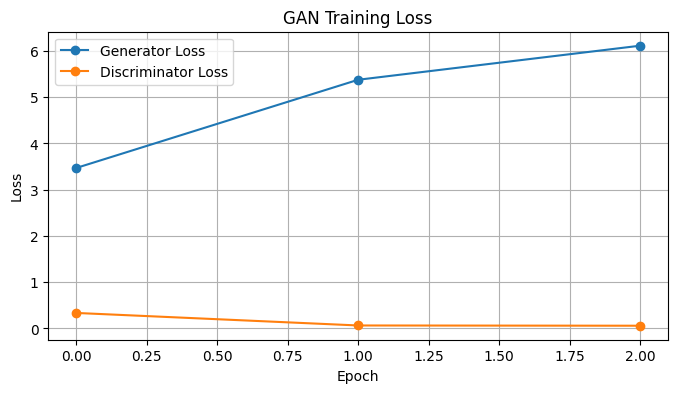

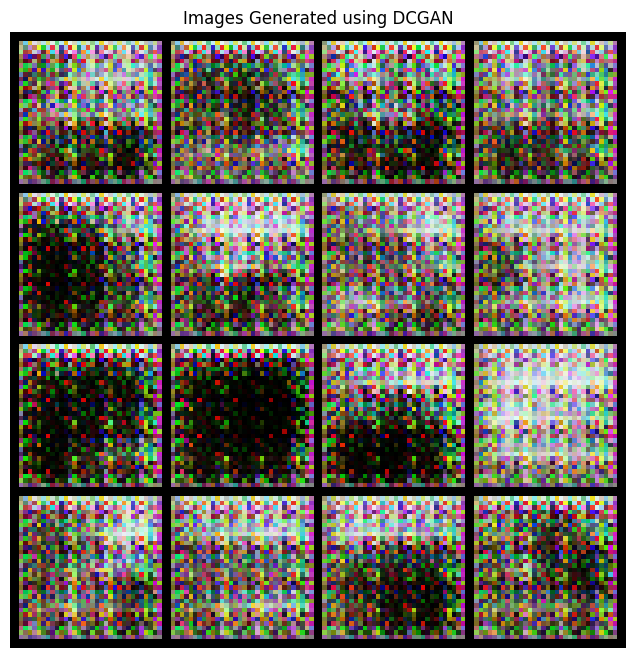

Generated images saved in generated_images/


In [ ]:
# ==========================================
# Exp-10: Image Generation using GAN
# ==========================================

# Step 1: Import Required Libraries
import os
import time
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Step 2: Configure Device and Parameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 100
batch_size = 64
num_epochs = 3
num_images = 2000
learning_rate = 0.0002

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA unavailable; using CPU.")

# Step 3: Load and Preprocess Dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

dataset = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=transform
)

dataset = Subset(dataset, range(num_images))

dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training images:", len(dataset))

# Step 4: Define Generator Network
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 256, 4, 1, 0),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.network(z)

# Step 5: Define Discriminator Network
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 1, 4, 1, 0)
        )

    def forward(self, images):
        return self.network(images).view(-1)

# Step 6: Initialize Models and Optimizers
generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer_G = torch.optim.Adam(
    generator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999)
)

optimizer_D = torch.optim.Adam(
    discriminator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999)
)

print("Generator and Discriminator initialized.")

# Step 7: Train the GAN
loss_G_history = []
loss_D_history = []
start_time = time.time()

for epoch in range(num_epochs):
    generator.train()
    discriminator.train()

    total_G_loss = 0
    total_D_loss = 0

    for real_images, _ in dataloader:
        real_images = real_images.to(
            device,
            non_blocking=(device.type == "cuda")
        )
        current_batch = real_images.size(0)

        # Train Discriminator
        noise = torch.randn(
            current_batch, latent_dim, 1, 1,
            device=device
        )
        fake_images = generator(noise)

        real_labels = torch.ones(current_batch, device=device)
        fake_labels = torch.zeros(current_batch, device=device)

        optimizer_D.zero_grad(set_to_none=True)

        real_output = discriminator(real_images)
        fake_output = discriminator(fake_images.detach())

        loss_real = criterion(real_output, real_labels)
        loss_fake = criterion(fake_output, fake_labels)
        loss_D = (loss_real + loss_fake) / 2

        loss_D.backward()
        optimizer_D.step()

        # Train Generator
        noise = torch.randn(
            current_batch, latent_dim, 1, 1,
            device=device
        )
        fake_images = generator(noise)

        optimizer_G.zero_grad(set_to_none=True)

        output = discriminator(fake_images)
        loss_G = criterion(output, real_labels)

        loss_G.backward()
        optimizer_G.step()

        total_D_loss += loss_D.item()
        total_G_loss += loss_G.item()

    avg_D_loss = total_D_loss / len(dataloader)
    avg_G_loss = total_G_loss / len(dataloader)

    loss_D_history.append(avg_D_loss)
    loss_G_history.append(avg_G_loss)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Discriminator Loss: {avg_D_loss:.4f} | "
        f"Generator Loss: {avg_G_loss:.4f}"
    )

print(f"Training time: {time.time() - start_time:.1f} seconds")

# Step 8: Plot Training Losses
plt.figure(figsize=(8, 4))
plt.plot(loss_G_history, marker="o", label="Generator Loss")
plt.plot(loss_D_history, marker="o", label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(True)
plt.show()

# Step 9: Generate New Images
generator.eval()
os.makedirs("generated_images", exist_ok=True)

with torch.no_grad():
    noise = torch.randn(
        16, latent_dim, 1, 1,
        device=device
    )

    generated_images = generator(noise).cpu()
    generated_images = (generated_images * 0.5 + 0.5).clamp(0, 1)

torchvision.utils.save_image(
    generated_images,
    "generated_images/gan_samples.png",
    nrow=4
)

# Step 10: Display Generated Images
grid = torchvision.utils.make_grid(
    generated_images,
    nrow=4
)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Images Generated using DCGAN")
plt.show()

print("Generated images saved in generated_images/")